# 🟢 ark-beta-mini-v3 — Image-to-Text (Classification + Sequence Generation)

## 🔴 Imports

In [64]:
from pathlib import Path
from datetime import datetime
import random, json, time, math, os, sys
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps, UnidentifiedImageError
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

## ⚙️ Configuration

In [65]:
ROOT = Path.cwd()
if not (ROOT / "dataset").exists() and (ROOT / "ark-vision" / "dataset").exists():
    ROOT = ROOT / "ark-vision"

DATA = ROOT / "dataset" / "Alphabet_VISION_Dataset"
TOKENIZER_PATH = ROOT / "tokenizer" / "bpe-tokenizer_alphabet_nlp_dataset_29,000.json"
MODEL_NAME = "ark-beta-mini-v3"
MODEL_LOGS = ROOT / "logs" / MODEL_NAME
MODEL_LOGS.mkdir(parents=True, exist_ok=True)

SELECTED_DATASETS = ["mnist_grayscale", "gender_face"]
IMAGE_WIDTH, IMAGE_HEIGHT = 100, 100  # retained only as reference; images are not resized
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_MODE = "L" if DEVICE.type == "cpu" else "RGB"
IMAGE_CHANNELS = 1 if IMAGE_MODE == "L" else 3

BATCH_SIZE = 8
# Number of NEW epochs to train on every notebook execution.
EPOCHS_PER_RUN = 10
LR = 1e-3
WEIGHT_DECAY = 0.0
NUM_WORKERS = 0
MAX_SEQUENCE_LENGTH = 64
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
MAX_GRAD_NORM = 1.0

if DEVICE.type == "cpu":
    torch.set_num_threads(2)

CLASS_NAMES = [str(i) for i in range(10)] + ["male", "female"]
LABEL_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print("Project root:", ROOT)
print("Dataset root:", DATA)
print("Tokenizer:", TOKENIZER_PATH, "| exists:", TOKENIZER_PATH.is_file())
print("Selected datasets:", SELECTED_DATASETS)
print(f"Image mode: {IMAGE_MODE} ({IMAGE_CHANNELS} channel(s)); original image dimensions preserved")
print("Device:", DEVICE)
print("Class labels:", CLASS_NAMES)

Project root: F:\pyvenv\ARK\ark-vision
Dataset root: F:\pyvenv\ARK\ark-vision\dataset\Alphabet_VISION_Dataset
Tokenizer: F:\pyvenv\ARK\ark-vision\tokenizer\bpe-tokenizer_alphabet_nlp_dataset_29,000.json | exists: True
Selected datasets: ['mnist_grayscale', 'gender_face']
Image mode: L (1 channel(s)); original image dimensions preserved
Device: cpu
Class labels: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'male', 'female']


## 🔤 BPE Tokenizer — Load and Smoke Test

In [66]:
try:
    from tokenizers import Tokenizer
except ImportError as exc:
    raise ImportError("کتابخانهٔ tokenizers نصب نیست. در صورت نیاز اجرا کنید: %pip install tokenizers") from exc

if not TOKENIZER_PATH.is_file():
    raise FileNotFoundError(f"Tokenizer JSON not found: {TOKENIZER_PATH}")

tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
# Add dedicated sequence markers for training. Existing vocabulary IDs remain unchanged.
tokenizer.add_special_tokens(["[PAD]", "[BOS]", "[EOS]"])
PAD_ID = tokenizer.token_to_id("[PAD]")
BOS_ID = tokenizer.token_to_id("[BOS]")
EOS_ID = tokenizer.token_to_id("[EOS]")
VOCAB_SIZE = tokenizer.get_vocab_size()

print(f"Tokenizer loaded: {TOKENIZER_PATH.name}")
print(f"Vocabulary size: {VOCAB_SIZE:,}")
print(f"Special IDs: PAD={PAD_ID}, BOS={BOS_ID}, EOS={EOS_ID}")

def tokenizer_smoke_test(text):
    encoded = tokenizer.encode(text)
    decoded = tokenizer.decode(encoded.ids, skip_special_tokens=True)
    print("Input:   ", repr(text))
    print("Token IDs:", encoded.ids[:40], ("..." if len(encoded.ids) > 40 else ""))
    print("Tokens:  ", encoded.tokens[:40], ("..." if len(encoded.tokens) > 40 else ""))
    print("Decoded: ", repr(decoded))
    print("Exact round-trip:", decoded == text)
    return encoded

# Check both scripts and a short English sample.
_ = tokenizer_smoke_test("سلام دنیا")
_ = tokenizer_smoke_test("می‌خواهم مدل تصویر به متن را آموزش دهم؛ نسخهٔ ۳.")
_ = tokenizer_smoke_test("مدل CNN برای Image-to-Text طراحی شده است.")
_ = tokenizer_smoke_test("Hello world")

Tokenizer loaded: bpe-tokenizer_alphabet_nlp_dataset_29,000.json
Vocabulary size: 29,876
Special IDs: PAD=29873, BOS=29874, EOS=29875
Input:    'سلام دنیا'
Token IDs: [5111, 2638] 
Tokens:   ['Ø³ÙĦØ§Ùħ', 'ĠØ¯ÙĨÛĮØ§'] 
Decoded:  'سلام دنیا'
Exact round-trip: True
Input:    'می\u200cخواهم مدل تصویر به متن را آموزش دهم؛ نسخهٔ ۳.'
Token IDs: [331, 1477, 152, 10870, 494, 1127, 213, 903, 237, 793, 10370, 317, 992, 132, 160, 1982, 15] 
Tokens:   ['ÙħÛĮ', 'âĢ', 'Į', 'Ø®ÙĪØ§ÙĩÙħ', 'ĠÙħØ¯ÙĦ', 'ĠØªØµÙĪÛĮØ±', 'ĠØ¨Ùĩ', 'ĠÙħØªÙĨ', 'ĠØ±Ø§', 'ĠØ¢ÙħÙĪØ²Ø´', 'ĠØ¯ÙĩÙħ', 'ØĽ', 'ĠÙĨØ³Ø®Ùĩ', 'Ù', 'Ķ', 'ĠÛ³', '.'] 
Decoded:  'می\u200cخواهم مدل تصویر به متن را آموزش دهم؛ نسخهٔ ۳.'
Exact round-trip: True
Input:    'مدل CNN برای Image-to-Text طراحی شده است.'
Token IDs: [2321, 5171, 276, 7337, 14, 4246, 14, 5497, 856, 336, 220, 15] 
Tokens:   ['ÙħØ¯ÙĦ', 'ĠCNN', 'ĠØ¨Ø±Ø§ÛĮ', 'ĠImage', '-', 'to', '-', 'Text', 'ĠØ·Ø±Ø§ØŃÛĮ', 'ĠØ´Ø¯Ùĩ', 'ĠØ§Ø³Øª', '.'] 
Decoded:  'مدل CNN برای Image-to-Text طراحی شده است.'
Exact rou

## 🗂️ Dataset — Image/Text Pairs

In [67]:
def prepare_image(image):
    """Convert to device-selected mode without resizing; preserve original pixel dimensions."""
    image = ImageOps.exif_transpose(image).convert(IMAGE_MODE)
    arr = np.asarray(image, dtype=np.float32).copy() / 255.0
    if IMAGE_MODE == "L":
        # (H, W) -> (1, H, W)
        arr = arr[None, :, :]
    else:
        # (H, W, C) -> (C, H, W)
        arr = arr.transpose(2, 0, 1)
    return torch.from_numpy(arr).contiguous()

def encode_caption(text):
    ids = tokenizer.encode(text).ids[:MAX_SEQUENCE_LENGTH-2]
    return [BOS_ID] + ids + [EOS_ID]

class ImageTextDataset(Dataset):
    def __init__(self, split):
        self.items, self.skipped = [], []
        split_root = DATA / split
        if not split_root.is_dir():
            raise FileNotFoundError(f"Split directory not found: {split_root}")
        for dataset_name in SELECTED_DATASETS:
            folder = split_root / dataset_name
            if not folder.is_dir():
                raise FileNotFoundError(f"Selected dataset folder not found: {folder}")
            for path in sorted(folder.rglob("*")):
                if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue
                label_path = path.with_suffix(".txt")
                if not label_path.is_file():
                    self.skipped.append((str(path), "missing .txt"))
                    continue
                text = label_path.read_text(encoding="utf-8-sig").strip()
                if not text:
                    self.skipped.append((str(path), "empty label"))
                    continue
                normalized = text.lower()
                if normalized in LABEL_TO_ID:
                    self.items.append((path, "class", LABEL_TO_ID[normalized], text))
                else:
                    ids = encode_caption(text)
                    if len(ids) < 2:
                        self.skipped.append((str(path), "empty token sequence"))
                        continue
                    self.items.append((path, "text", ids, text))
        if not self.items:
            raise ValueError(f"No image/text pairs found for split={split}")
        self.class_count = sum(item[1] == "class" for item in self.items)
        self.text_count = len(self.items) - self.class_count
        print(f"{split}: {len(self.items):,} samples | classes={self.class_count:,} | sequences={self.text_count:,} | skipped={len(self.skipped):,}")
        if self.skipped[:3]:
            print("Skipped examples:", self.skipped[:3])

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, kind, target, text = self.items[idx]
        try:
            with Image.open(path) as im:
                image = prepare_image(im)
        except (UnidentifiedImageError, OSError) as exc:
            raise RuntimeError(f"Could not read image {path}: {exc}") from exc
        if kind == "class":
            return image, 0, target, [], text, str(path)
        return image, 1, -1, target, text, str(path)

def collate_batch(batch):
    images, kinds, class_targets, seq_targets, texts, paths = zip(*batch)
    # Pad only to the largest H/W in this batch; never resize the source images.
    channels = images[0].shape[0]
    max_h = max(img.shape[1] for img in images)
    max_w = max(img.shape[2] for img in images)
    padded_images = torch.zeros((len(images), channels, max_h, max_w), dtype=images[0].dtype)
    for i, img in enumerate(images):
        _, h, w = img.shape
        padded_images[i, :, :h, :w] = img
    images = padded_images
    kinds = torch.tensor(kinds, dtype=torch.long)
    class_targets = torch.tensor(class_targets, dtype=torch.long)
    max_len = max((len(s) for s in seq_targets), default=0)
    seq_tensor = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)
    for i, seq in enumerate(seq_targets):
        if seq:
            seq_tensor[i, :len(seq)] = torch.tensor(seq, dtype=torch.long)
    return images, kinds, class_targets, seq_tensor, list(texts), list(paths)

train_dataset = ImageTextDataset("train")
valid_dataset = ImageTextDataset("valid")
test_dataset = ImageTextDataset("test")

print("Sample label examples:")
for ds in (train_dataset,):
    for item in ds.items[:5]:
        print(item[0].name, "=>", repr(item[3]))

train: 1,120 samples | classes=1,120 | sequences=0 | skipped=0
valid: 280 samples | classes=280 | sequences=0 | skipped=0
test: 280 samples | classes=280 | sequences=0 | skipped=0
Sample label examples:
0_1.png => '0'
0_10.png => '0'
0_11.png => '0'
0_12.png => '0'
0_13.png => '0'


## 🔄 DataLoaders

In [68]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, collate_fn=collate_batch)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=collate_batch)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, collate_fn=collate_batch)

batch = next(iter(train_loader))
print("Image batch:", tuple(batch[0].shape))
print("Task kinds (0=class, 1=sequence):", batch[1].tolist())
print("Class targets:", batch[2].tolist())
print("Sequence target shape:", tuple(batch[3].shape))
print("Train/valid/test:", len(train_dataset), len(valid_dataset), len(test_dataset))

Image batch: (8, 1, 100, 71)
Task kinds (0=class, 1=sequence): [0, 0, 0, 0, 0, 0, 0, 0]
Class targets: [3, 8, 7, 3, 5, 10, 5, 9]
Sequence target shape: (8, 0)
Train/valid/test: 1120 280 280


## 💾 Checkpointing — Save and Resume

In [69]:
# True: resume from latest.pt (falls back to best.pt for older checkpoints).
# False: start a new training run.
AUTO_RESUME = True

MODEL_LOGS = Path(MODEL_LOGS)
MODEL_LOGS.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# Find the newest run with a resumable checkpoint. Prefer latest.pt,
# because best.pt may belong to an earlier epoch with a better validation loss.
checkpoint_runs = [
    p for p in MODEL_LOGS.iterdir()
    if p.is_dir() and ((p / "latest.pt").is_file() or (p / "best.pt").is_file())
]

if AUTO_RESUME and checkpoint_runs:
    RUN_DIR = max(
        checkpoint_runs,
        key=lambda p: max(
            (p / name).stat().st_mtime
            for name in ("latest.pt", "best.pt")
            if (p / name).is_file()
        )
    )
    RESUME_RUN_ID = RUN_DIR.name
    RESUMING = True
else:
    RUN_DIR = MODEL_LOGS / RUN_ID
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    RESUME_RUN_ID = None
    RESUMING = False

LATEST_CHECKPOINT_PATH = RUN_DIR / "latest.pt"
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
# Backward-compatible alias used by the test cells below.
CHECKPOINT_PATH = BEST_CHECKPOINT_PATH
RESUME_CHECKPOINT_PATH = (
    LATEST_CHECKPOINT_PATH if LATEST_CHECKPOINT_PATH.is_file()
    else BEST_CHECKPOINT_PATH
)
HISTORY_PATH = RUN_DIR / "history.json"
PLOT_PATH = RUN_DIR / "training_plot.png"
TRAINING_LOG_PATH = RUN_DIR / "training.txt"

# ---------------------------------------------------------
# Training state
# ---------------------------------------------------------

accumulated_training_time = 0.0
start_epoch = 1
history = {
    "train_loss": [],
    "valid_loss": [],
    "valid_class_accuracy": [],
}
best_val_loss = float("inf")


def log_training(message):
    """Append a timestamped message to training.txt."""
    timestamp = datetime.now().isoformat(timespec="seconds")
    line = f"[{timestamp}] {message}"
    print(line)

    with open(TRAINING_LOG_PATH, "a", encoding="utf-8") as f:
        f.write(line + "\n")


# Create the log immediately.
with open(TRAINING_LOG_PATH, "a", encoding="utf-8") as f:
    f.write(
        f"\n=== {'Resume' if RESUMING else 'New run'}: "
        f"{datetime.now().isoformat(timespec='seconds')} ===\n"
    )
    f.write(
        f"Device: {DEVICE} | image mode: {IMAGE_MODE} | "
        f"channels: {IMAGE_CHANNELS}\n"
    )

# ---------------------------------------------------------
# Save checkpoint
# ---------------------------------------------------------

def save_checkpoint(
    path,
    model,
    optimizer,
    epoch,
    best_val_loss,
    history,
):
    """Save model, optimizer and training state."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    checkpoint = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict()
            if optimizer is not None else None,
        "epoch": int(epoch),
        "best_val_loss": float(best_val_loss),
        "accumulated_training_time": float(
            accumulated_training_time
        ),
        "history": history,
        "class_names": list(CLASS_NAMES),
        "vocab_size": int(VOCAB_SIZE),
        "tokenizer_path": str(TOKENIZER_PATH),
        "selected_datasets": list(SELECTED_DATASETS),
        "image_size": [IMAGE_WIDTH, IMAGE_HEIGHT],
        "image_channels": int(IMAGE_CHANNELS),
        "image_mode": str(IMAGE_MODE),
        "max_sequence_length": int(MAX_SEQUENCE_LENGTH),
    }

    # Write to a temporary file first, then replace the target.
    temp_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(checkpoint, temp_path)
    temp_path.replace(path)

    log_training(
        f"Checkpoint saved: {path} | epoch={epoch} | "
        f"best_val_loss={best_val_loss:.6f}"
    )


# ---------------------------------------------------------
# Load checkpoint
# Call this only AFTER model and optimizer are created.
# ---------------------------------------------------------

def load_checkpoint(path, model, optimizer=None):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"Checkpoint not found: {path}"
        )

    checkpoint = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False,
    )

    # Validate configuration before loading weights.
    saved_classes = checkpoint.get("class_names")
    saved_vocab_size = checkpoint.get("vocab_size")
    saved_channels = checkpoint.get(
        "image_channels", IMAGE_CHANNELS
    )
    saved_mode = checkpoint.get("image_mode", IMAGE_MODE)
    saved_image_size = checkpoint.get(
        "image_size", [IMAGE_WIDTH, IMAGE_HEIGHT]
    )
    saved_max_seq = checkpoint.get(
        "max_sequence_length", MAX_SEQUENCE_LENGTH
    )

    mismatches = []

    if saved_classes is not None and saved_classes != list(CLASS_NAMES):
        mismatches.append(
            f"class_names: saved={saved_classes}, "
            f"current={list(CLASS_NAMES)}"
        )

    if saved_vocab_size is not None and saved_vocab_size != VOCAB_SIZE:
        mismatches.append(
            f"vocab_size: saved={saved_vocab_size}, "
            f"current={VOCAB_SIZE}"
        )

    if saved_channels != IMAGE_CHANNELS:
        mismatches.append(
            f"image_channels: saved={saved_channels}, "
            f"current={IMAGE_CHANNELS}"
        )

    if saved_mode != IMAGE_MODE:
        mismatches.append(
            f"image_mode: saved={saved_mode}, "
            f"current={IMAGE_MODE}"
        )

    if list(saved_image_size) != [IMAGE_WIDTH, IMAGE_HEIGHT]:
        mismatches.append(
            f"image_size: saved={saved_image_size}, "
            f"current={[IMAGE_WIDTH, IMAGE_HEIGHT]}"
        )

    if saved_max_seq != MAX_SEQUENCE_LENGTH:
        mismatches.append(
            f"max_sequence_length: saved={saved_max_seq}, "
            f"current={MAX_SEQUENCE_LENGTH}"
        )

    if mismatches:
        raise ValueError(
            "Checkpoint configuration does not match the current run:\n- "
            + "\n- ".join(mismatches)
            + "\nUse the matching model/data configuration or start a new run."
        )

    # load_state_dict will also detect architecture/weight shape mismatches.
    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None:
        optimizer_state = checkpoint.get("optimizer_state_dict")
        if optimizer_state is not None:
            optimizer.load_state_dict(optimizer_state)

    return checkpoint


# ---------------------------------------------------------
# Restore state AFTER creating model and optimizer
# ---------------------------------------------------------

def restore_training_state(model, optimizer):
    global start_epoch
    global best_val_loss
    global accumulated_training_time
    global history

    if not RESUMING:
        log_training("Starting a new training run.")
        return

    # Prefer latest.pt. Legacy runs containing only best.pt are also supported.
    resume_path = (
        LATEST_CHECKPOINT_PATH if LATEST_CHECKPOINT_PATH.is_file()
        else BEST_CHECKPOINT_PATH
    )
    log_training(f"Loading checkpoint: {resume_path}")

    checkpoint = load_checkpoint(
        resume_path,
        model,
        optimizer,
    )

    start_epoch = int(checkpoint.get("epoch", 0)) + 1
    best_val_loss = float(
        checkpoint.get("best_val_loss", float("inf"))
    )
    accumulated_training_time = float(
        checkpoint.get("accumulated_training_time", 0.0)
    )

    saved_history = checkpoint.get("history")
    if isinstance(saved_history, dict):
        history = saved_history

    # Ensure expected keys exist for older checkpoints.
    for key in (
        "train_loss",
        "valid_loss",
        "valid_class_accuracy",
    ):
        history.setdefault(key, [])

    log_training(
        f"Resumed successfully | next_epoch={start_epoch} | "
        f"best_val_loss={best_val_loss:.6f} | "
        f"previous_training_time={accumulated_training_time:.1f}s"
    )


# ---------------------------------------------------------
# Initial status
# ---------------------------------------------------------

print("Run directory:", RUN_DIR)
print("Resume enabled:", RESUMING)
print("Latest checkpoint path:", LATEST_CHECKPOINT_PATH)
print("Best checkpoint path:", BEST_CHECKPOINT_PATH)
print("Resume source:", RESUME_CHECKPOINT_PATH)
print("Training log:", TRAINING_LOG_PATH)
print("History path:", HISTORY_PATH)

Run directory: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36
Resume enabled: True
Latest checkpoint path: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\latest.pt
Best checkpoint path: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\best.pt
Resume source: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\latest.pt
Training log: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\training.txt
History path: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\history.json


## 🧠 Model Architecture — BetaMini Multi-Task CNN + GRU

In [70]:
class BetaMiniV3(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(IMAGE_CHANNELS, 8, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.image_projection = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 4 * 4, HIDDEN_DIM), nn.ReLU(inplace=True)
        )
        self.class_head = nn.Linear(HIDDEN_DIM, len(CLASS_NAMES))
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBEDDING_DIM, padding_idx=PAD_ID)
        self.init_hidden = nn.Linear(HIDDEN_DIM, HIDDEN_DIM)
        self.decoder = nn.GRU(EMBEDDING_DIM, HIDDEN_DIM, batch_first=True)
        self.token_head = nn.Linear(HIDDEN_DIM, VOCAB_SIZE)

    def encode_image(self, images):
        return self.image_projection(self.features(images))

    def forward(self, images, decoder_input=None):
        image_features = self.encode_image(images)
        class_logits = self.class_head(image_features)
        token_logits = None
        if decoder_input is not None and decoder_input.shape[1] > 0:
            hidden = torch.tanh(self.init_hidden(image_features)).unsqueeze(0)
            embeddings = self.embedding(decoder_input)
            decoded, _ = self.decoder(embeddings, hidden)
            token_logits = self.token_head(decoded)
        return class_logits, token_logits

    @torch.no_grad()
    def generate(self, images, max_length=MAX_SEQUENCE_LENGTH):
        self.eval()
        image_features = self.encode_image(images)
        hidden = torch.tanh(self.init_hidden(image_features)).unsqueeze(0)
        current = torch.full((images.size(0), 1), BOS_ID, dtype=torch.long, device=images.device)
        generated = []
        finished = torch.zeros(images.size(0), dtype=torch.bool, device=images.device)
        for _ in range(max_length):
            out, hidden = self.decoder(self.embedding(current[:, -1:]), hidden)
            next_id = self.token_head(out[:, -1]).argmax(dim=-1)
            generated.append(next_id)
            finished |= next_id.eq(EOS_ID)
            current = next_id.unsqueeze(1)
            if finished.all():
                break
        if not generated:
            return torch.empty((images.size(0), 0), dtype=torch.long, device=images.device)
        return torch.stack(generated, dim=1)

model = BetaMiniV3().to(DEVICE)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Model: ARK Beta Mini v3")
print("Device:", DEVICE)
print(f"Trainable parameters: {trainable_params:,}")
print("Tasks: class classification + token sequence generation")
print(f"Image input channels: {IMAGE_CHANNELS} ({IMAGE_MODE})")
print(
    f"Class count: {len(CLASS_NAMES)} | "
    f"Tokenizer vocabulary: {VOCAB_SIZE:,}"
)

Model: ARK Beta Mini v3
Device: cpu
Trainable parameters: 7,866,816
Tasks: class classification + token sequence generation
Image input channels: 1 (L)
Class count: 12 | Tokenizer vocabulary: 29,876


## 🏋️ Training and Validation

[2026-10-23T10:06:00] Loading checkpoint: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\latest.pt
[2026-10-23T10:06:00] Resumed successfully | next_epoch=21 | best_val_loss=0.589056 | previous_training_time=174.0s
This session will train 10 additional epoch(s): 21 through 30.
[2026-10-23T10:06:00] Session target: 10 additional epochs; epoch range=21-30.
Epoch 21/30 | train loss=0.2714 | valid loss=0.7315 | valid class acc=80.71% | epoch time=7.2s | accumulated training time=181.3s (3.02 min)
[2026-10-23T10:06:08] Epoch 21/30 | train loss=0.2714 | valid loss=0.7315 | valid class acc=80.71% | epoch time=7.2s | accumulated training time=181.3s (3.02 min)
[2026-10-23T10:06:08] Checkpoint saved: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\latest.pt | epoch=21 | best_val_loss=0.589056
Epoch 22/30 | train loss=0.2925 | valid loss=0.6875 | valid class acc=81.79% | epoch time=7.1s | accumulated training time=188.3s (3.14 min)
[2026-10-23T10:06:15] Epo

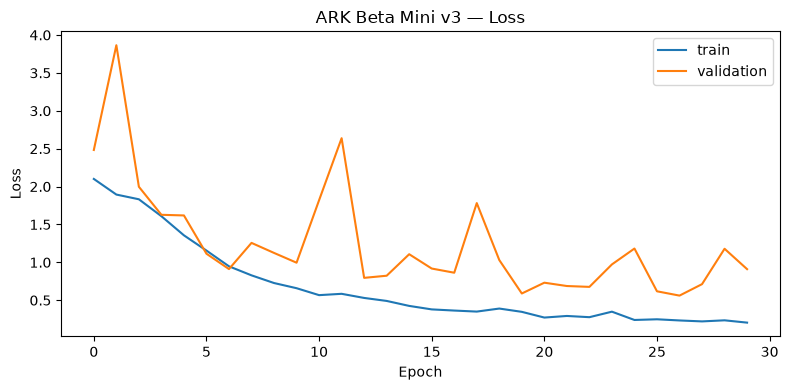

History saved: F:\pyvenv\ARK\ark-vision\logs\ark-beta-mini-v3\2026-10-23_10-01-36\history.json


In [71]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    class_loss_sum = 0.0
    seq_loss_sum = 0.0
    class_n = 0
    seq_tokens = 0
    class_correct = 0
    batches = 0

    for images, kinds, class_targets, seq_targets, _, _ in loader:
        images = images.to(DEVICE)
        kinds = kinds.to(DEVICE)
        class_targets = class_targets.to(DEVICE)
        seq_targets = seq_targets.to(DEVICE)
        class_mask = kinds.eq(0)
        seq_mask = kinds.eq(1)
        optimizer and optimizer.zero_grad(set_to_none=True)

        # Sequence decoder receives tokens except the final target token.
        decoder_input = seq_targets[:, :-1] if seq_targets.shape[1] > 1 else seq_targets[:, :0]
        class_logits, token_logits = model(images, decoder_input if decoder_input.shape[1] else None)
        loss = torch.zeros((), device=DEVICE)

        if class_mask.any():
            c_loss = nn.functional.cross_entropy(class_logits[class_mask], class_targets[class_mask])
            loss = loss + c_loss
            class_loss_sum += c_loss.item() * int(class_mask.sum().item())
            class_n += int(class_mask.sum().item())
            class_correct += (class_logits[class_mask].argmax(dim=1) == class_targets[class_mask]).sum().item()

        if seq_mask.any() and token_logits is not None and seq_targets.shape[1] > 1:
            targets = seq_targets[:, 1:]
            active_logits = token_logits[seq_mask]
            active_targets = targets[seq_mask]
            s_loss = nn.functional.cross_entropy(
                active_logits.reshape(-1, VOCAB_SIZE),
                active_targets.reshape(-1),
                ignore_index=PAD_ID
            )
            loss = loss + s_loss
            valid_tokens = int(active_targets.ne(PAD_ID).sum().item())
            seq_loss_sum += s_loss.item() * max(valid_tokens, 1)
            seq_tokens += valid_tokens

        if training:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimizer.step()
        total_loss += loss.item()
        batches += 1

    return {
        "loss": total_loss / max(batches, 1),
        "class_loss": class_loss_sum / max(class_n, 1),
        "sequence_token_loss": seq_loss_sum / max(seq_tokens, 1),
        "class_accuracy": class_correct / max(class_n, 1),
        "class_samples": class_n,
        "sequence_tokens": seq_tokens,
    }

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# Critical: restore model, optimizer, epoch, history and cumulative time
# AFTER both model and optimizer exist.
restore_training_state(model, optimizer)
last_completed_epoch = start_epoch - 1

# Every execution trains EPOCHS_PER_RUN additional epochs, starting from
# the last completed epoch stored in latest.pt (or the available legacy checkpoint).
target_epoch = last_completed_epoch + EPOCHS_PER_RUN
print(
    f"This session will train {EPOCHS_PER_RUN} additional epoch(s): "
    f"{start_epoch} through {target_epoch}."
)
log_training(
    f"Session target: {EPOCHS_PER_RUN} additional epochs; "
    f"epoch range={start_epoch}-{target_epoch}."
)

for epoch in range(start_epoch, target_epoch + 1):
    start = time.time()

    train_metrics = run_epoch(model, train_loader, optimizer)
    valid_metrics = run_epoch(model, valid_loader)

    epoch_time = time.time() - start
    accumulated_training_time += epoch_time
    last_completed_epoch = epoch

    history["train_loss"].append(train_metrics["loss"])
    history["valid_loss"].append(valid_metrics["loss"])
    history["valid_class_accuracy"].append(valid_metrics["class_accuracy"])

    log_message = (
        f"Epoch {epoch:02d}/{target_epoch} | "
        f"train loss={train_metrics['loss']:.4f} | "
        f"valid loss={valid_metrics['loss']:.4f} | "
        f"valid class acc={valid_metrics['class_accuracy']:.2%} | "
        f"epoch time={epoch_time:.1f}s | "
        f"accumulated training time={accumulated_training_time:.1f}s "
        f"({accumulated_training_time / 60:.2f} min)"
    )

    print(log_message)
    log_training(log_message)

    is_best = valid_metrics["loss"] < best_val_loss
    if is_best:
        best_val_loss = valid_metrics["loss"]

    # Always save the latest state, even when validation loss did not improve.
    # This preserves the actual completed epoch and cumulative training time.
    save_checkpoint(
        LATEST_CHECKPOINT_PATH, model, optimizer,
        epoch, best_val_loss, history
    )
    if is_best:
        save_checkpoint(
            BEST_CHECKPOINT_PATH, model, optimizer,
            epoch, best_val_loss, history
        )

    # Persist human-readable history after every epoch, not only at the end.
    with open(HISTORY_PATH, "w", encoding="utf-8") as f:
        json.dump(history, f, ensure_ascii=False, indent=2)

final_summary = (
    "\nTraining session finished.\n"
    f"Additional epochs requested this session: {EPOCHS_PER_RUN}\n"
    f"Target cumulative epoch: {target_epoch}\n"
    f"Last completed epoch: {last_completed_epoch}\n"
    f"Accumulated training time: "
    f"{accumulated_training_time:.1f}s "
    f"({accumulated_training_time / 60:.2f} min, "
    f"{accumulated_training_time / 3600:.2f} hours)\n"
    f"Best validation loss: {best_val_loss:.6f}\n"
)

print(final_summary)
log_training(final_summary)
print("Training log saved:", TRAINING_LOG_PATH)

with open(HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(history, f, ensure_ascii=False, indent=2)

plt.figure(figsize=(8, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["valid_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ARK Beta Mini v3 — Loss")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=150)
plt.show()
print("History saved:", HISTORY_PATH)

## 🔴 Test — Classification and Sequence Generation

In [72]:
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError("No checkpoint found. Run the training section first.")

checkpoint = load_checkpoint(CHECKPOINT_PATH, model)
model.eval()

class_correct = [0] * len(CLASS_NAMES)
class_total = [0] * len(CLASS_NAMES)
all_text_examples = []
test_loss_sum = 0.0
test_batches = 0

with torch.no_grad():
    for images, kinds, class_targets, seq_targets, texts, paths in test_loader:
        images = images.to(DEVICE)
        kinds = kinds.to(DEVICE)
        class_targets = class_targets.to(DEVICE)
        seq_targets = seq_targets.to(DEVICE)
        class_logits, token_logits = model(
            images,
            seq_targets[:, :-1] if seq_targets.shape[1] > 1 else None
        )
        losses = []
        class_mask = kinds.eq(0)
        seq_mask = kinds.eq(1)
        if class_mask.any():
            losses.append(nn.functional.cross_entropy(class_logits[class_mask], class_targets[class_mask]).item())
            pred = class_logits[class_mask].argmax(1)
            for t, p in zip(class_targets[class_mask].cpu().tolist(), pred.cpu().tolist()):
                class_total[t] += 1
                class_correct[t] += int(t == p)
        if seq_mask.any() and token_logits is not None and seq_targets.shape[1] > 1:
            losses.append(nn.functional.cross_entropy(
                token_logits[seq_mask].reshape(-1, VOCAB_SIZE),
                seq_targets[seq_mask, 1:].reshape(-1),
                ignore_index=PAD_ID
            ).item())
        if losses:
            test_loss_sum += sum(losses) / len(losses)
            test_batches += 1

        text_indices = torch.where(seq_mask)[0]
        if len(text_indices):
            generated = model.generate(images[text_indices])
            for local_i, row in zip(text_indices.cpu().tolist(), generated.cpu().tolist()):
                cleaned = []
                for token_id in row:
                    if token_id == EOS_ID:
                        break
                    if token_id not in (PAD_ID, BOS_ID):
                        cleaned.append(token_id)
                prediction_text = tokenizer.decode(cleaned, skip_special_tokens=True)
                all_text_examples.append((texts[local_i], prediction_text, paths[local_i]))

print("=" * 60)
print("Test loss:", f"{test_loss_sum / max(test_batches, 1):.6f}")
total_class = sum(class_total)
correct_class = sum(class_correct)
print(f"Classification accuracy: {correct_class / max(total_class, 1):.2%} ({correct_class}/{total_class})")
print("Per-class accuracy:")
for i, name in enumerate(CLASS_NAMES):
    if class_total[i]:
        print(f"  {name:>6}: {class_correct[i] / class_total[i]:.2%} ({class_correct[i]}/{class_total[i]})")
    else:
        print(f"  {name:>6}: no test samples")

print("\nGenerated text examples (reference => prediction):")
for reference, prediction, path in all_text_examples[:20]:
    print(f"REF : {reference}")
    print(f"PRED: {prediction}")
    print(f"FILE: {path}\n")
print("=" * 60)

Test loss: 0.811898
Classification accuracy: 83.93% (235/280)
Per-class accuracy:
       0: 95.00% (19/20)
       1: 100.00% (20/20)
       2: 100.00% (20/20)
       3: 80.00% (16/20)
       4: 95.00% (19/20)
       5: 95.00% (19/20)
       6: 75.00% (15/20)
       7: 65.00% (13/20)
       8: 60.00% (12/20)
       9: 90.00% (18/20)
    male: 75.00% (30/40)
  female: 85.00% (34/40)

Generated text examples (reference => prediction):


## 🔴 Random Visual Test — Image-to-Text

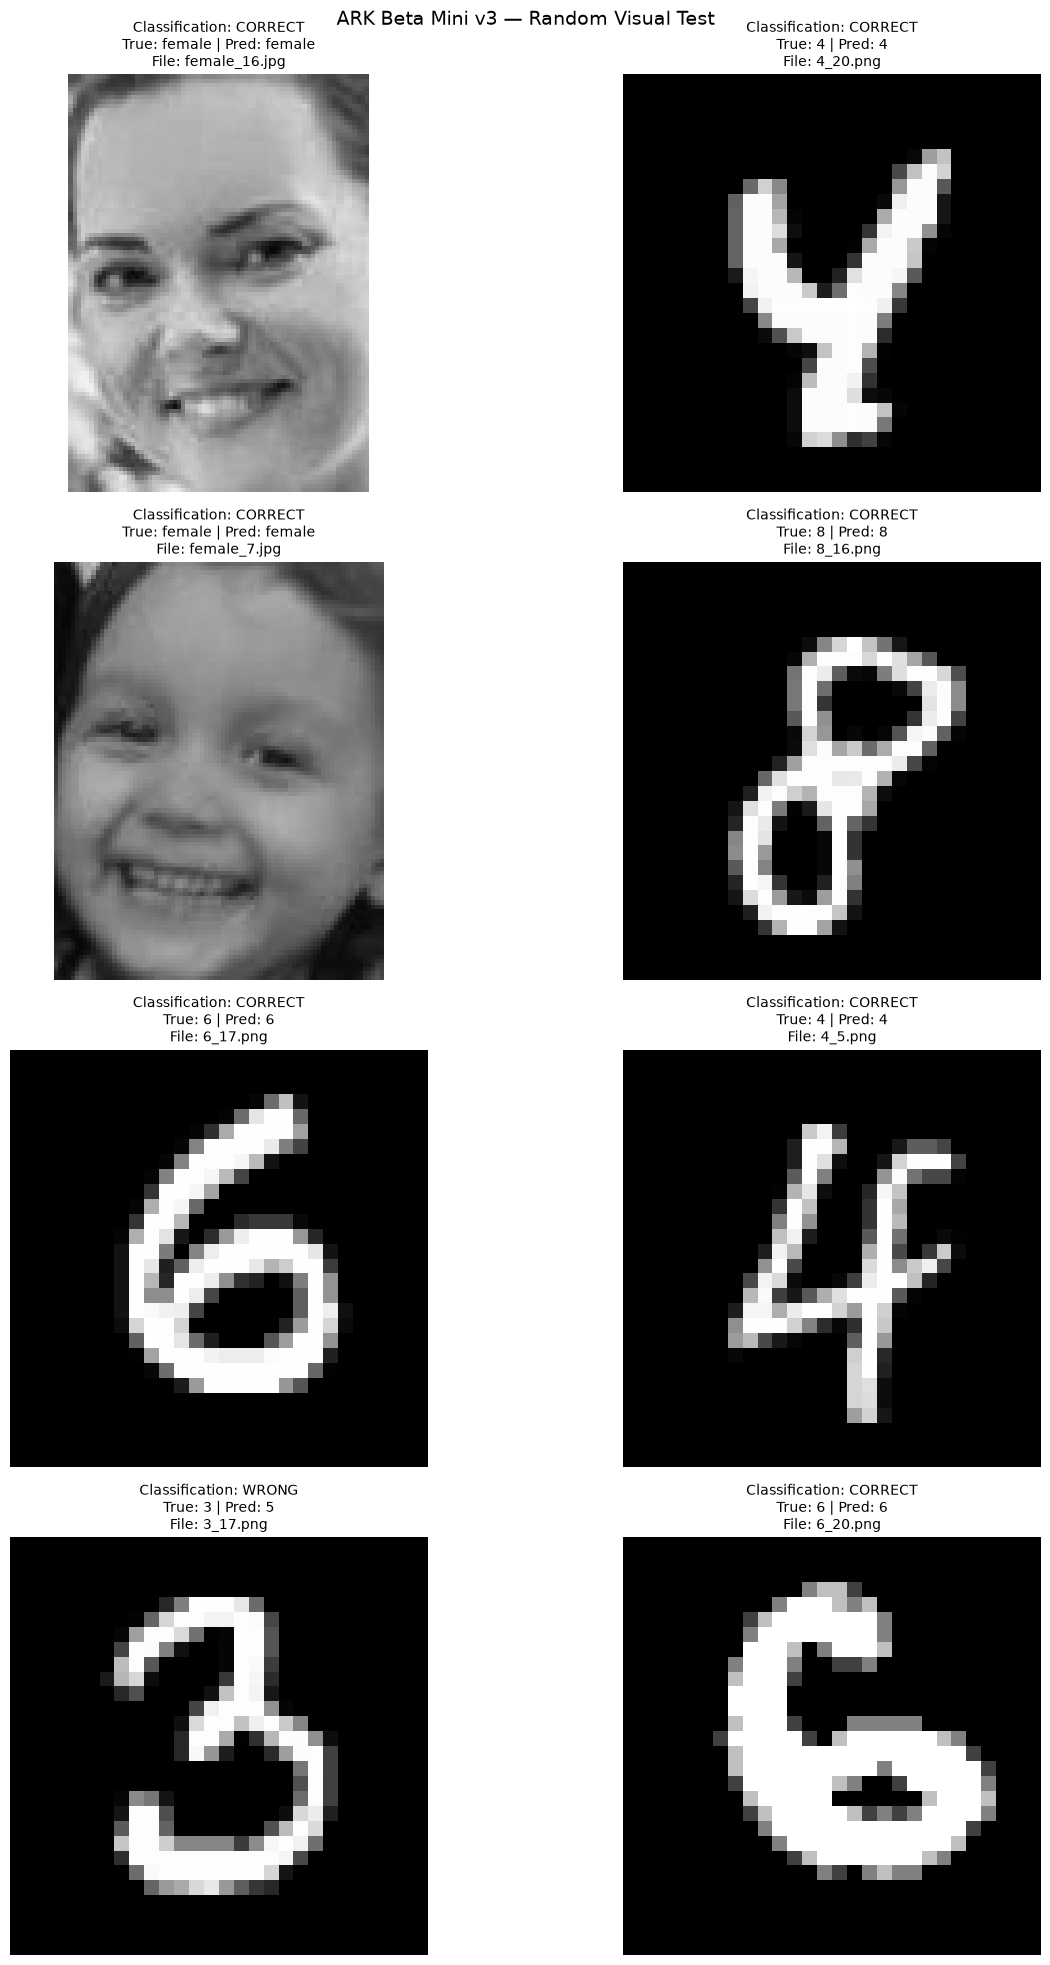

In [73]:
def random_visual_test(dataset=test_dataset, n_samples=8, seed=None):
    if len(dataset) == 0:
        print("Dataset is empty.")
        return

    rng = random.Random(seed)
    indices = rng.sample(
        range(len(dataset)),
        k=min(n_samples, len(dataset))
    )

    model.eval()

    n_cols = 2
    n_rows = (len(indices) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(14, 5 * n_rows),
        squeeze=False
    )
    axes = axes.flatten()

    with torch.no_grad():
        for ax, idx in zip(axes, indices):
            image, kind, class_target, seq_target, reference, path = dataset[idx]

            image_batch = image.unsqueeze(0).to(DEVICE)
            class_logits, _ = model(image_batch)

            # Display grayscale on CPU and RGB on CUDA.
            display_image = image.detach().cpu()
            if display_image.shape[0] == 1:
                ax.imshow(np.clip(display_image.squeeze(0).numpy(), 0.0, 1.0), cmap="gray", vmin=0.0, vmax=1.0)
            else:
                ax.imshow(np.clip(display_image.permute(1, 2, 0).numpy(), 0.0, 1.0))
            ax.axis("off")

            if kind == 0:
                # Classification
                pred_id = class_logits.argmax(dim=1).item()
                predicted = CLASS_NAMES[pred_id]

                status = (
                    "CORRECT"
                    if predicted == reference.lower()
                    else "WRONG"
                )

                ax.set_title(
                    f"Classification: {status}\n"
                    f"True: {reference} | Pred: {predicted}\n"
                    f"File: {Path(path).name}",
                    fontsize=10
                )

            else:
                # Sequence generation
                generated_ids = model.generate(
                    image_batch,
                    max_length=MAX_SEQUENCE_LENGTH
                )[0].cpu().tolist()

                cleaned_ids = []

                for token_id in generated_ids:
                    if token_id == EOS_ID:
                        break
                    if token_id not in (PAD_ID, BOS_ID):
                        cleaned_ids.append(token_id)

                predicted = tokenizer.decode(
                    cleaned_ids,
                    skip_special_tokens=True
                )

                ax.set_title(
                    f"Text Generation\n"
                    f"True: {reference[:100]}\n"
                    f"Pred: {predicted[:100]}\n"
                    f"File: {Path(path).name}",
                    fontsize=9
                )

    for ax in axes[len(indices):]:
        ax.axis("off")

    fig.suptitle(
        "ARK Beta Mini v3 — Random Visual Test",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

random_visual_test(n_samples=8, seed=None)